# FieldFlow LangGraph Flow Visualizer
Run the cells below in Jupyter or VS Code / Cursor to view the LangGraph execution structure.

In [3]:
import importlib
from IPython.display import display, Markdown, Image
import core.graph

# 1. Force reload core.graph so any updates on disk are reflected in RAM
importlib.reload(core.graph)
from core.graph import compiled_chat_graph

# 2. Extract the compiled graph structure
graph = compiled_chat_graph.get_graph(xray=True)
mermaid_syntax = graph.draw_mermaid()

# 3. Render Mermaid visually inside Jupyter
display(Markdown("```mermaid\n" + mermaid_syntax + "\n```"))


```mermaid
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	route_intent(route_intent)
	cancel(cancel)
	greeting(greeting)
	mid_greeting(mid_greeting)
	select_form(select_form)
	switch_form(switch_form)
	multi_action_override(multi_action_override)
	plan_or_classify(plan_or_classify)
	field_answer(field_answer)
	check_remaining(check_remaining)
	ask_missing(ask_missing)
	prepare_review(prepare_review)
	__end__([<p>__end__</p>]):::last
	__start__ --> route_intent;
	check_remaining -.-> ask_missing;
	check_remaining -.-> prepare_review;
	field_answer -.-> __end__;
	field_answer -.-> check_remaining;
	multi_action_override -.-> __end__;
	multi_action_override -.-> check_remaining;
	plan_or_classify -.-> __end__;
	plan_or_classify -.-> check_remaining;
	route_intent -.-> cancel;
	route_intent -.-> field_answer;
	route_intent -.-> greeting;
	route_intent -.-> mid_greeting;
	route_intent -.-> multi_action_override;
	route_intent -.-> plan_or_classify;
	route_intent -.-> select_form;
	route_intent -.-> switch_form;
	select_form --> check_remaining;
	switch_form --> check_remaining;
	ask_missing --> __end__;
	cancel --> __end__;
	greeting --> __end__;
	mid_greeting --> __end__;
	prepare_review --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc

```

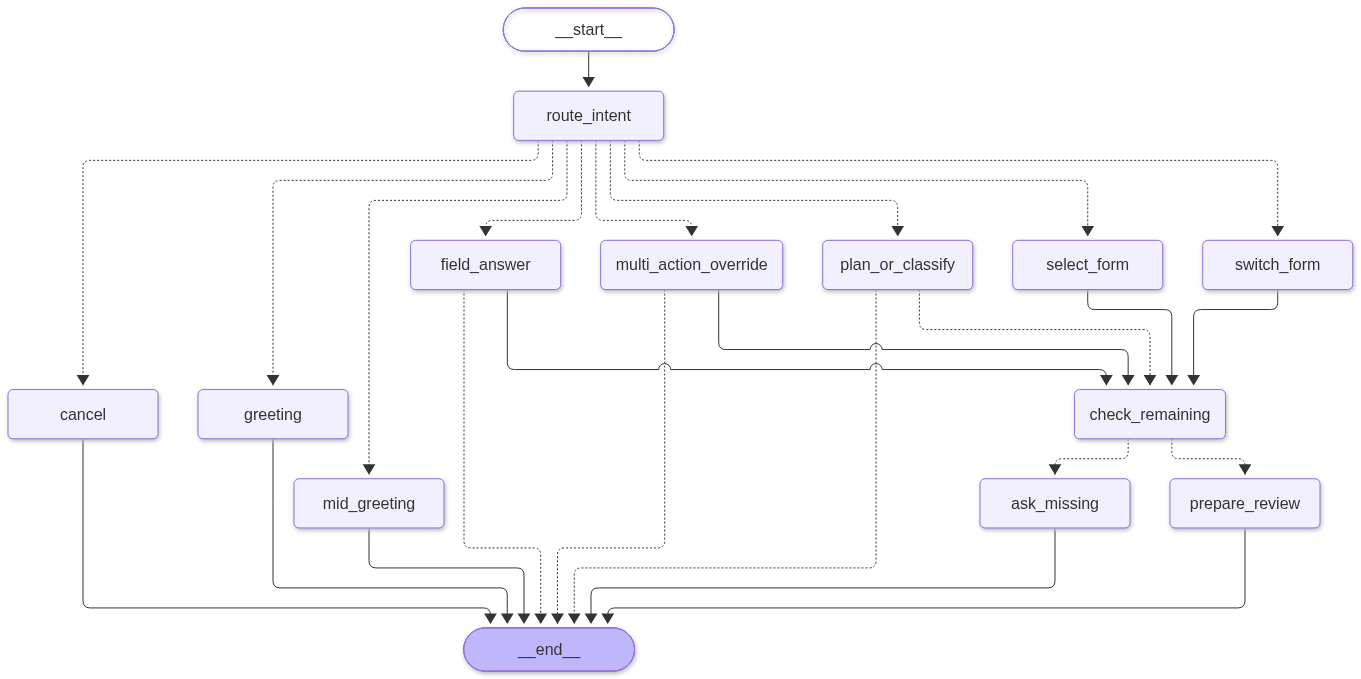

In [4]:
# 4. Render as PNG image (if online mermaid.ink is accessible)
try:
    png_data = graph.draw_mermaid_png()
    display(Image(png_data))
except Exception as e:
    print("Note: Online PNG rendering via mermaid.ink is offline or restricted:", e)
    print("The native Mermaid diagram in the cell above renders locally without internet.")
